In [2]:
# Day 26 — Customer Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("transformed_retail_sales.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Month_Name,Quarter,Profit_Margin,Order_Value,Customer_Segment,Sales_Category,Profit_Category,Customer_Type,Product_Performance,Order_Size
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,November,4,16.00,261.9600,Low Value,Low,Profit,Consumer,Good,Small
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,November,4,30.00,731.9400,Low Value,Low,Profit,Consumer,Good,Small
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,June,2,47.00,14.6200,Low Value,Low,Profit,Corporate,Good,Small
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,October,4,-40.00,957.5775,Low Value,Low,Loss,Consumer,Needs Improvement,Large
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,October,4,11.25,22.3680,Low Value,Low,Profit,Consumer,Good,Small


In [4]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Year', 'Month', 'Month_Name', 'Quarter', 'Profit_Margin', 'Order_Value', 'Customer_Segment', 'Sales_Category', 'Profit_Category', 'Customer_Type', 'Product_Performance', 'Order_Size']


In [5]:
# Task 1 — Customer Revenue

customer_sales = df.groupby("Customer ID")["Sales"].sum()

print(customer_sales)

Customer ID
AA-10315    5563.560
AA-10375    1056.390
AA-10480    1790.512
AA-10645    5086.935
AB-10015     886.156
              ...   
XP-21865    2374.658
YC-21895    5454.350
YS-21880    6720.444
ZC-21910    8025.707
ZD-21925    1493.944
Name: Sales, Length: 793, dtype: float64


In [6]:
# Task 2 — Top 10 Customers

top_10_customers = customer_sales.sort_values(ascending=False).head(10)

print(top_10_customers)

Customer ID
SM-20320    25043.050
TC-20980    19052.218
RB-19360    15117.339
TA-21385    14595.620
AB-10105    14473.571
KL-16645    14175.229
SC-20095    14142.334
HL-15040    12873.298
SE-20110    12209.438
CC-12370    12129.072
Name: Sales, dtype: float64


In [7]:
# Top 20 Customers

top_20_customers = customer_sales.sort_values(ascending=False).head(20)

print(top_20_customers)

Customer ID
SM-20320    25043.050
TC-20980    19052.218
RB-19360    15117.339
TA-21385    14595.620
AB-10105    14473.571
KL-16645    14175.229
SC-20095    14142.334
HL-15040    12873.298
SE-20110    12209.438
CC-12370    12129.072
TS-21370    11891.751
GT-14710    11820.120
BM-11140    11789.630
SV-20365    11470.950
CJ-12010    11164.974
CL-12565    10880.546
ME-17320    10663.728
KF-16285    10604.266
BS-11365    10501.653
EH-13765    10310.880
Name: Sales, dtype: float64


In [8]:
# Task 3 — Average Customer Spending

total_customer_sales = df["Sales"].sum()

total_customers = df["Customer ID"].nunique()

average_spending = total_customer_sales / total_customers

print("Average Customer Spending:", average_spending)

Average Customer Spending: 2896.848499747793


In [9]:
# Task 4 — Repeat Customers

orders_per_customer = df.groupby("Customer ID")["Order ID"].nunique()

repeat_customers = orders_per_customer[orders_per_customer > 1]

print(repeat_customers)

Customer ID
AA-10315     5
AA-10375     9
AA-10480     4
AA-10645     6
AB-10015     3
            ..
XP-21865    11
YC-21895     5
YS-21880     8
ZC-21910    13
ZD-21925     5
Name: Order ID, Length: 781, dtype: int64


In [10]:
# Task 5 — Customer Contribution

customer_contribution = (customer_sales / customer_sales.sum()) * 100

print(customer_contribution)

Customer ID
AA-10315    0.242189
AA-10375    0.045986
AA-10480    0.077943
AA-10645    0.221441
AB-10015    0.038575
              ...   
XP-21865    0.103372
YC-21895    0.237435
YS-21880    0.292549
ZC-21910    0.349369
ZD-21925    0.065033
Name: Sales, Length: 793, dtype: float64


In [11]:
# Task 6 — Customer Segments

customer_segments = customer_sales.to_frame(name="Sales")

customer_segments["Segment"] = pd.qcut(
    customer_segments["Sales"].rank(method="first"),
    q=3,
    labels=["Low Value", "Medium Value", "High Value"]
)

print(customer_segments)

                Sales       Segment
Customer ID                        
AA-10315     5563.560    High Value
AA-10375     1056.390     Low Value
AA-10480     1790.512  Medium Value
AA-10645     5086.935    High Value
AB-10015      886.156     Low Value
...               ...           ...
XP-21865     2374.658  Medium Value
YC-21895     5454.350    High Value
YS-21880     6720.444    High Value
ZC-21910     8025.707    High Value
ZD-21925     1493.944  Medium Value

[793 rows x 2 columns]


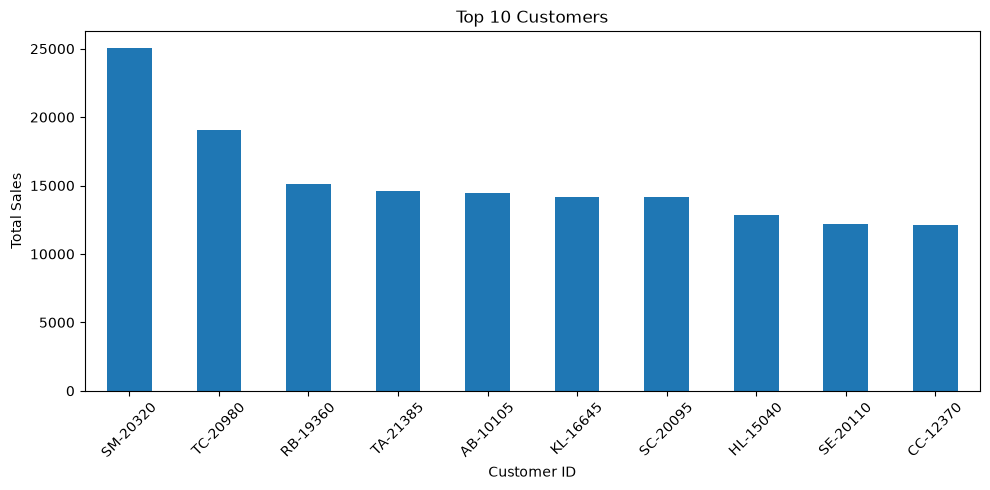

In [12]:
# Task 7 — Top 10 Customers

import matplotlib.pyplot as plt

top_10_customers = customer_sales.sort_values(ascending=False).head(10)

top_10_customers.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Customers")
plt.xlabel("Customer ID")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

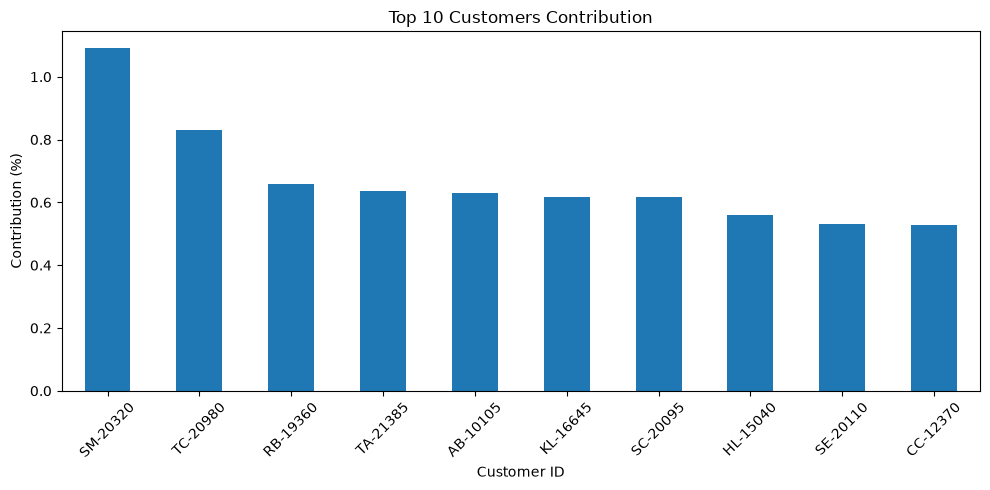

In [13]:
# Customer Contribution Visualization

customer_contribution.sort_values(ascending=False).head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Customers Contribution")
plt.xlabel("Customer ID")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

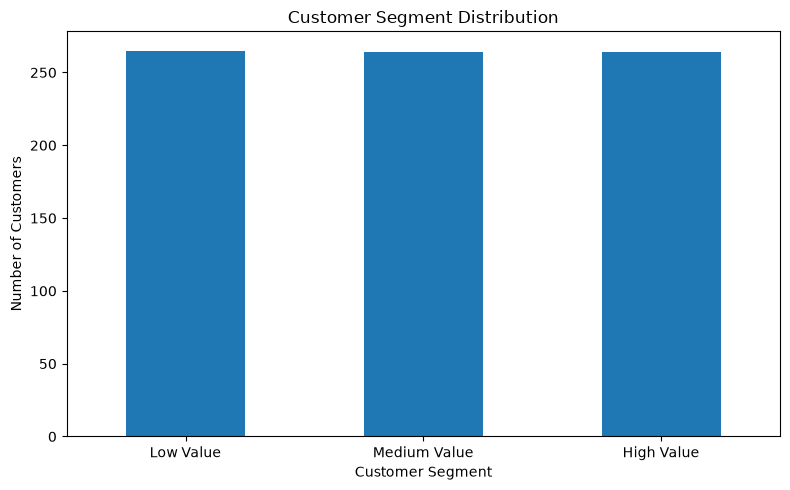

In [14]:
# Customer Segment Distribution

customer_segments["Segment"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

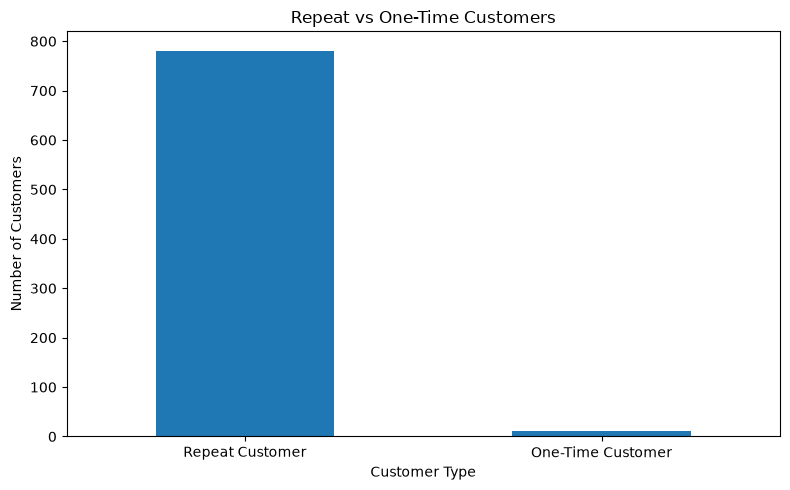

In [15]:
# Repeat vs One-Time Customers

customer_type = orders_per_customer.apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)

customer_type.value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Repeat vs One-Time Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()